# Data Analysis: Design of Experiments (DOE)

> **Who is this for:** a beginner who knows basic statistics (mean, variance, t-test) and wants to learn how to **plan** experiments so the data give a clear answer: in a factory, a lab, a web product, or when tuning ML models. Also for BS/MS students in a "Design of Experiments" / "Advanced Statistics" course, and for data-science interviews about A/B testing.
>
> **What you will learn:**
> - the four principles: **randomisation, replication, blocking, control**, and how **confounding** ruins unplanned comparisons
> - the **completely randomised design** and **one-way ANOVA** (from scratch, then statsmodels), with **Tukey HSD** post-hoc comparisons
> - the **randomised block design** and the **Latin square**, with the variance-reduction gain quantified
> - **2^k full factorial** designs: main effects, interactions, interaction plots; **fractional factorials**, resolution and aliasing
> - **response surface methodology** with a **central composite design**, compared with Bayesian optimisation
> - **power and sample size** for ANOVA and factorial designs
> - online-experiment extensions: **CUPED**, **switchback** designs, **interference** / network effects
> - **experimenting on ML systems**: a factorial ablation of hyperparameters analysed with ANOVA
>
> **Prerequisites:** [statistics](08_statistics.ipynb), [statistical modelling and inference](13_statistical_modeling_and_inference.ipynb). Helpful: [A/B testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, simulated processes with known truth.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

An **experiment** is a fair test: you change something on purpose (a fertiliser, a website button, a learning rate) and measure what happens. **Design of experiments** is the art of planning that test so the answer is clear and cheap. The first rule is to **let chance decide** who gets which treatment (randomisation), otherwise you might give the new fertiliser only to the sunniest fields and fool yourself. The second rule is to **repeat** the test enough times so luck averages out. The third is to **compare like with like** (blocking): test both fertilisers inside the same field, so the difference between fields does not get in the way. Smart designs can also test **several factors at once**, and even find the best combination of settings with few trials.

**Everyday examples:**
- Testing two pizza-dough recipes: you bake both on the **same day in the same oven** (blocking), several times (replication), and you flip a coin to decide which goes on the top shelf (randomisation).
- A running coach tests "new shoes" and "more sleep" at the same time with 4 combinations (old/new shoes × short/long sleep): this is a **factorial design**, and it also reveals whether the shoes only help when you are well rested (an **interaction**).

**Tiny example:** 6 tomato plants, 3 get fertiliser A, 3 get B (chosen by drawing names from a hat). Yields: A = 4, 5, 6 kg, B = 6, 7, 8 kg. The averages are 5 and 7 kg: B looks better by 2 kg. Because the plants were assigned at random and each group has 3 plants, we can calculate how likely a 2 kg gap would be by pure luck.

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Randomisation + replication | let chance assign treatments, and repeat | clinical trials, A/B tests on websites and apps |
| Blocking / factorial design | compare inside similar groups; vary several things at once | agriculture, factories, ablation studies of ML models |
| Response surface / CUPED / switchback | find the best settings; reduce noise; test when users affect each other | tuning chemical processes, online platforms such as ride-hailing and marketplaces |

### How this notebook is different from its neighbours

| Notebook | Focus |
|---|---|
| [11_ab_testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb) | two-arm online tests: sample size, peeking, Bayesian A/B, bandits |
| [24_Research_Methods/02_experiment_design_for_ml](../24_Research_Methods/02_experiment_design_for_ml.ipynb) | designing ML research experiments: baselines, seeds, ablations |
| [04_uncommon_models/02 (Gaussian-process process optimisation)](../03_Machine_Learning/04_uncommon_models/02_industry_gaussian_process_process_optimization.ipynb) | Bayesian optimisation of a process |
| **This notebook** | classical DOE: ANOVA, blocking, Latin squares, factorial and fractional designs, response surfaces, power; plus their online and ML extensions |

## 0. Setup

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import itertools, warnings
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.power import FTestAnovaPower
print("ready")

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


ready


---
## 1. Principles: randomisation, replication, blocking, control

> 💬 **In plain English:** a fair test lets chance decide who gets the treatment, repeats it, and compares like with like.

**Vocabulary** (R. A. Fisher, *The Design of Experiments*, 1935, from field trials at Rothamsted):

| Term | Meaning | Example |
|---|---|---|
| **Factor** | something you change on purpose | fertiliser type |
| **Level** | a value of a factor | A, B, C, D |
| **Treatment** | one combination of factor levels | fertiliser B at 20 kg/ha |
| **Experimental unit** | the thing that receives a treatment independently | one plot of land |
| **Response** | what you measure | yield (kg) |
| **Nuisance factor** | affects the response but is not of interest | soil quality, the day, the operator |
| **Block** | a group of similar units | the plots in one field |

The four principles:
1. **Randomisation**: assign treatments to units by a random mechanism. It balances *all* nuisance factors, known and unknown, on average, and justifies the probability statements of the analysis.
2. **Replication**: several units per treatment. It lets you estimate the noise and makes means precise. (Measuring the same unit twice is *not* replication; it is **pseudo-replication**.)
3. **Blocking**: group similar units and randomise **within** each group, to remove a known nuisance factor from the comparison ("block what you can, randomise what you cannot").
4. **Control**: a comparison group (placebo, current version), and holding everything else fixed (same procedures, blinding where possible).

**Confounding** happens when the treatment is mixed up with another cause of the response. Below, farmers choose where to put the new fertiliser and, naturally, use it on their best (sunniest) plots.

True effect = 1.00 t/ha
Farmers' choice: estimate = 1.96  (mean sun treated 0.61 vs untreated 0.38)
Randomised     : estimate = 1.07  (mean sun treated 0.53 vs untreated 0.49)


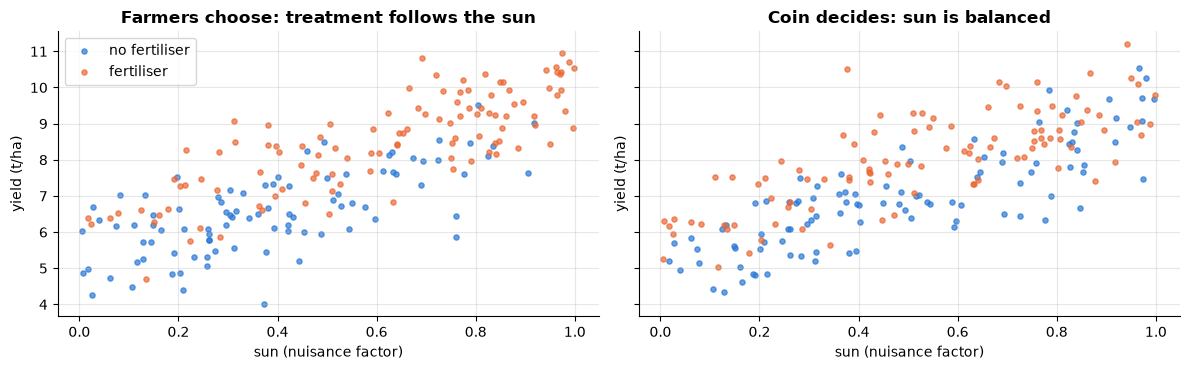

In [2]:
rng = np.random.default_rng(1)
n_plots = 200
sun = rng.uniform(0, 1, n_plots)                        # nuisance factor: hours of sun (scaled 0..1)
TRUE_EFFECT = 1.0                                       # fertiliser adds 1.0 t/ha

def yield_of(treated):
    return 5 + 4 * sun + TRUE_EFFECT * treated + rng.normal(0, 0.8, n_plots)

# (a) farmers' choice: sunnier plots are more likely to get fertiliser
chosen = (rng.uniform(0, 1, n_plots) < 0.15 + 0.7 * sun).astype(int)
y_obs = yield_of(chosen)
naive = y_obs[chosen == 1].mean() - y_obs[chosen == 0].mean()

# (b) randomised: a coin decides
coin = rng.permutation(np.repeat([0, 1], n_plots // 2))
y_rand = yield_of(coin)
randomised = y_rand[coin == 1].mean() - y_rand[coin == 0].mean()

print(f"True effect = {TRUE_EFFECT:.2f} t/ha")
print(f"Farmers' choice: estimate = {naive:.2f}  (mean sun treated {sun[chosen == 1].mean():.2f} vs untreated {sun[chosen == 0].mean():.2f})")
print(f"Randomised     : estimate = {randomised:.2f}  (mean sun treated {sun[coin == 1].mean():.2f} vs untreated {sun[coin == 0].mean():.2f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, t, yy, title in [(axes[0], chosen, y_obs, "Farmers choose: treatment follows the sun"),
                          (axes[1], coin, y_rand, "Coin decides: sun is balanced")]:
    ax.scatter(sun[t == 0], yy[t == 0], s=14, alpha=0.7, label="no fertiliser")
    ax.scatter(sun[t == 1], yy[t == 1], s=14, alpha=0.7, label="fertiliser")
    ax.set(title=title, xlabel="sun (nuisance factor)", ylabel="yield (t/ha)")
axes[0].legend(); plt.tight_layout(); plt.show()

**What just happened?** When farmers chose, the treated plots were also the sunnier ones, so the naive difference mixes the fertiliser effect with the sun effect and overstates it. With a coin, sun is balanced between the groups and the estimate is close to the true 1.0 t/ha. Randomisation did this without us even measuring sun: it would also balance factors nobody thought of.

> ⚠️ **Common mistake:** "haphazard" assignment (the technician picks "at random" in their head) is not randomisation. Use a random number generator and record the seed.

---
## 2. Completely randomised design (CRD) and one-way ANOVA

> 💬 **In plain English:** give each treatment to random units, then check whether the group averages differ more than luck allows.

In a **CRD**, all units are assigned to the $t$ treatments completely at random (usually $r$ units each). The model is

$$y_{ij} = \mu + \tau_i + \varepsilon_{ij}, \qquad \varepsilon_{ij} \sim N(0, \sigma^2) \text{ independent}$$

**One-way ANOVA** (analysis of variance) tests $H_0: \tau_1 = \dots = \tau_t = 0$ by splitting the total variation into **between-treatment** and **within-treatment** (error) parts:

| Source | Sum of squares | df | Mean square | F |
|---|---|---|---|---|
| Treatments | $SS_T = \sum_i r_i (\bar y_{i\cdot} - \bar y_{\cdot\cdot})^2$ | $t - 1$ | $MS_T = SS_T/(t-1)$ | $MS_T / MS_E$ |
| Error | $SS_E = \sum_i\sum_j (y_{ij} - \bar y_{i\cdot})^2$ | $N - t$ | $MS_E = SS_E/(N-t)$ | |
| Total | $SS_{tot} = \sum (y_{ij} - \bar y_{\cdot\cdot})^2$ | $N - 1$ | | |

Under $H_0$, $F \sim F_{t-1,\,N-t}$. Intuition: if treatments do nothing, the treatment means vary only by noise, so $MS_T$ and $MS_E$ estimate the same $\sigma^2$ and F ≈ 1.

**Worked example by hand** (the tomatoes from above plus a third fertiliser C = 5, 6, 7):

| | values | mean |
|---|---|---|
| A | 4, 5, 6 | 5 |
| B | 6, 7, 8 | 7 |
| C | 5, 6, 7 | 6 |

Grand mean 6. $SS_T = 3[(5-6)^2 + (7-6)^2 + (6-6)^2] = 6$, $SS_E = 3 \times (1 + 0 + 1) = 6$, so $MS_T = 6/2 = 3$, $MS_E = 6/6 = 1$, $F = 3$ with (2, 6) df.

In [3]:
def one_way_anova(groups):
    """groups: list of 1-D arrays. Returns a dict with the ANOVA table numbers."""
    allv = np.concatenate(groups)
    N, t, grand = len(allv), len(groups), allv.mean()
    ss_t = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_e = sum(((g - g.mean()) ** 2).sum() for g in groups)
    ms_t, ms_e = ss_t / (t - 1), ss_e / (N - t)
    F = ms_t / ms_e
    return {"SS_T": ss_t, "SS_E": ss_e, "df_T": t - 1, "df_E": N - t, "MS_T": ms_t, "MS_E": ms_e,
            "F": F, "p": stats.f.sf(F, t - 1, N - t), "eta2": ss_t / (ss_t + ss_e)}

hand = one_way_anova([np.array([4., 5, 6]), np.array([6., 7, 8]), np.array([5., 6, 7])])
print({k: round(v, 4) for k, v in hand.items()})
assert np.isclose(hand["F"], 3.0)

{'SS_T': np.float64(6.0), 'SS_E': np.float64(6.0), 'df_T': 2, 'df_E': 6, 'MS_T': np.float64(3.0), 'MS_E': np.float64(1.0), 'F': np.float64(3.0), 'p': np.float64(0.125), 'eta2': np.float64(0.5)}


Now a realistic CRD: **4 fertilisers, 6 plots each**, assigned at random. The true means are 20, 21, 23.5 and 20.5 t/ha with σ = 1.5.

In [4]:
rng = np.random.default_rng(10)
true_means = {"A": 20.0, "B": 21.0, "C": 23.5, "D": 20.5}
plots = rng.permutation(np.repeat(list(true_means), 6))           # the random assignment of 24 plots
crd = pd.DataFrame({"plot": np.arange(1, 25), "fert": plots})
crd["yield_t"] = crd["fert"].map(true_means) + rng.normal(0, 1.5, len(crd))
print("Randomised layout (plot -> fertiliser):", "".join(crd["fert"]))
print(crd.groupby("fert")["yield_t"].agg(["count", "mean", "std"]).round(2))

ours = one_way_anova([g.to_numpy() for _, g in crd.groupby("fert")["yield_t"]])
model = smf.ols("yield_t ~ C(fert)", data=crd).fit()
table = sm.stats.anova_lm(model, typ=1)
print(table.round(4))
assert np.isclose(ours["F"], table.loc["C(fert)", "F"]) and np.isclose(ours["F"], stats.f_oneway(*[g for _, g in crd.groupby("fert")["yield_t"]]).statistic)
print(f"\nFrom scratch: F = {ours['F']:.3f}, p = {ours['p']:.2e}, eta² = {ours['eta2']:.2f} (share of variance explained by fertiliser)")
print(f"Levene test for equal variances: p = {stats.levene(*[g for _, g in crd.groupby('fert')['yield_t']]).pvalue:.2f}")

Randomised layout (plot -> fertiliser): BBBACDDBAACDBDCACACDBDAC
      count   mean   std
fert                    
A         6  20.14  0.51
B         6  20.78  1.97
C         6  22.94  1.78
D         6  20.18  1.19
            df   sum_sq  mean_sq       F  PR(>F)
C(fert)    3.0  31.4280  10.4760  4.7965  0.0112
Residual  20.0  43.6814   2.1841     NaN     NaN

From scratch: F = 4.797, p = 1.12e-02, eta² = 0.42 (share of variance explained by fertiliser)
Levene test for equal variances: p = 0.07


**What just happened?** Our ANOVA, statsmodels' `anova_lm` and scipy's `f_oneway` give the same F. A small p-value says *at least one* fertiliser differs, but not *which*. Levene's test does not reject equal variances, so the classic ANOVA assumption is plausible.

### 2.1 Post-hoc comparisons: Tukey HSD

Comparing all $\binom{4}{2} = 6$ pairs with ordinary t-tests would inflate the family-wise error rate. **Tukey's Honestly Significant Difference** test controls it for **all pairwise comparisons**, using the **studentized range** distribution:

$$q_{ij} = \frac{|\bar y_i - \bar y_j|}{\sqrt{\frac{MS_E}{2}\left(\frac{1}{n_i} + \frac{1}{n_j}\right)}}, \qquad p_{ij} = P(Q_{t,\,N-t} > q_{ij})$$

In [5]:
means = crd.groupby("fert")["yield_t"].mean(); counts = crd.groupby("fert").size()
t_groups, df_e = len(means), ours["df_E"]
q_crit = stats.studentized_range.ppf(0.95, t_groups, df_e)
rows = []
for a, b in itertools.combinations(means.index, 2):
    se = np.sqrt(ours["MS_E"] / 2 * (1 / counts[a] + 1 / counts[b]))
    q = abs(means[b] - means[a]) / se
    rows.append({"group1": a, "group2": b, "meandiff": means[b] - means[a],
                 "p-adj (ours)": stats.studentized_range.sf(q, t_groups, df_e),
                 "half-width of 95% CI": q_crit * se})
ours_tukey = pd.DataFrame(rows)
sm_tukey = pairwise_tukeyhsd(crd["yield_t"], crd["fert"], alpha=0.05)
ours_tukey["p-adj (statsmodels)"] = sm_tukey.pvalues
ours_tukey["reject H0"] = sm_tukey.reject
print(ours_tukey.round(4).to_string(index=False))
assert np.allclose(ours_tukey["p-adj (ours)"], sm_tukey.pvalues, atol=1e-3)

group1 group2  meandiff  p-adj (ours)  half-width of 95% CI  p-adj (statsmodels)  reject H0
     A      B    0.6415        0.8748                2.3882               0.8748      False
     A      C    2.8054        0.0178                2.3882               0.0178       True
     A      D    0.0434        1.0000                2.3882               1.0000      False
     B      C    2.1638        0.0844                2.3882               0.0844      False
     B      D   -0.5981        0.8955                2.3882               0.8955      False
     C      D   -2.7620        0.0198                2.3882               0.0198       True


**What just happened?** Our Tukey p-values match statsmodels. Read the `reject H0` column: **C** (the truly best fertiliser) is significantly better than A and D; C vs B is borderline (B happened to have a high-variance sample), and the differences of 0.5–1 t/ha among A, B and D are within the noise for 6 plots per group. A non-significant pair is not proof of "no difference": its CI half-width (about 2.4 t/ha here) is wider than the true gaps.

**Complexity of the analysis:** ANOVA is $O(N)$ (one pass for means and sums of squares); Tukey is $O(t^2)$ comparisons.

> 🎓 **Exam / interview tip:** ANOVA's F-test is "omnibus": significant F, then post-hoc tests (Tukey for all pairs, **Dunnett** for "each vs control", Bonferroni/Holm for a few planned contrasts). Plan the contrasts you care about **before** seeing the data.

---
## 3. Randomised complete block design (RCBD) and Latin squares

> 💬 **In plain English:** compare treatments inside similar groups (fields, drivers, cars) so their differences do not hide the effect.

### 3.1 RCBD
If the plots come from **5 different fields** with very different soil, a CRD would mix field differences into the error term. In an **RCBD**, each field (block) contains **all 4 fertilisers once**, randomised within the field:

$$y_{ij} = \mu + \tau_i + \beta_j + \varepsilon_{ij}$$

```
field 1:  C  A  D  B        each row is a block;
field 2:  B  D  A  C        inside each block the order is random;
field 3:  A  C  B  D        every treatment appears once per block
field 4:  D  B  C  A
field 5:  A  D  B  C
```

The block sum of squares $SS_B = t \sum_j (\bar y_{\cdot j} - \bar y_{\cdot\cdot})^2$ is removed from the error, so $MS_E$ is smaller and the test is more powerful. The price: $b - 1$ degrees of freedom for the blocks.

In [6]:
def rcbd_anova(Y):
    """Y: b x t array (rows = blocks, columns = treatments). Returns SS, df, F, p for an additive model."""
    b, t = Y.shape
    grand = Y.mean()
    ss_trt = b * ((Y.mean(axis=0) - grand) ** 2).sum()
    ss_blk = t * ((Y.mean(axis=1) - grand) ** 2).sum()
    ss_tot = ((Y - grand) ** 2).sum()
    ss_e = ss_tot - ss_trt - ss_blk
    df_e = (b - 1) * (t - 1)
    ms_trt, ms_blk, ms_e = ss_trt / (t - 1), ss_blk / (b - 1), ss_e / df_e
    return {"F_trt": ms_trt / ms_e, "p_trt": stats.f.sf(ms_trt / ms_e, t - 1, df_e), "MS_E": ms_e, "MS_blk": ms_blk}

rng = np.random.default_rng(4)
b, t = 5, 4
tau = np.array([0.0, 1.0, 2.5, 0.5])                    # treatment effects (A, B, C, D)
field = rng.normal(0, 3.0, b)                            # big field-to-field differences
Y = 20 + field[:, None] + tau[None, :] + rng.normal(0, 1.0, (b, t))
long = pd.DataFrame([{"field": f"F{i+1}", "fert": "ABCD"[j], "y": Y[i, j]} for i in range(b) for j in range(t)])

res_rcbd = rcbd_anova(Y)
res_crd = one_way_anova([Y[:, j] for j in range(t)])      # WRONG analysis: ignore the blocks
print(sm.stats.anova_lm(smf.ols("y ~ C(fert) + C(field)", data=long).fit(), typ=2).round(4))
print(f"\nRCBD analysis : F = {res_rcbd['F_trt']:.2f}, p = {res_rcbd['p_trt']:.4f}, MS_E = {res_rcbd['MS_E']:.2f}")
print(f"Ignoring block: F = {res_crd['F']:.2f}, p = {res_crd['p']:.4f}, MS_E = {res_crd['MS_E']:.2f}")
# Relative efficiency of the RCBD vs a CRD with the same units (Montgomery's formula)
re_ = ((b - 1) * res_rcbd["MS_blk"] + b * (t - 1) * res_rcbd["MS_E"]) / ((b * t - 1) * res_rcbd["MS_E"])
print(f"Estimated relative efficiency RCBD vs CRD = {re_:.1f}: a CRD would need about {re_:.1f} x as many plots for the same precision")

            sum_sq    df        F  PR(>F)
C(fert)    30.3506   3.0   7.9023  0.0036
C(field)  217.1185   4.0  42.3981  0.0000
Residual   15.3629  12.0      NaN     NaN

RCBD analysis : F = 7.90, p = 0.0036, MS_E = 1.28
Ignoring block: F = 0.70, p = 0.5678, MS_E = 14.53
Estimated relative efficiency RCBD vs CRD = 9.7: a CRD would need about 9.7 x as many plots for the same precision


**What just happened?** The same 20 numbers analysed two ways. Ignoring the fields leaves the big field-to-field variation in the error ($MS_E$ is large) and the fertiliser effect is hidden. The block analysis removes it and finds the effect clearly. The **relative efficiency** says how many times more plots a CRD would need for the same precision.

Is this luck of one dataset? A **power simulation** repeats the experiment 2,000 times:

In [7]:
rng = np.random.default_rng(5)
SIMS = 2000
Ys = 20 + rng.normal(0, 3.0, (SIMS, b, 1)) + tau[None, None, :] + rng.normal(0, 1.0, (SIMS, b, t))

def rcbd_p_batch(Ys):
    grand = Ys.mean(axis=(1, 2), keepdims=True)
    ss_trt = b * ((Ys.mean(axis=1, keepdims=True) - grand) ** 2).sum(axis=(1, 2))
    ss_blk = t * ((Ys.mean(axis=2, keepdims=True) - grand) ** 2).sum(axis=(1, 2))
    ss_e = ((Ys - grand) ** 2).sum(axis=(1, 2)) - ss_trt - ss_blk
    df_e = (b - 1) * (t - 1)
    return stats.f.sf((ss_trt / (t - 1)) / (ss_e / df_e), t - 1, df_e)

def crd_p_batch(Ys):
    grand = Ys.mean(axis=(1, 2), keepdims=True)
    ss_trt = b * ((Ys.mean(axis=1, keepdims=True) - grand) ** 2).sum(axis=(1, 2))
    ss_e = ((Ys - Ys.mean(axis=1, keepdims=True)) ** 2).sum(axis=(1, 2))
    return stats.f.sf((ss_trt / (t - 1)) / (ss_e / (b * t - t)), t - 1, b * t - t)

p_r, p_c = rcbd_p_batch(Ys), crd_p_batch(Ys)
assert np.isclose(p_r[0], rcbd_anova(Ys[0])["p_trt"]) and np.isclose(p_c[0], one_way_anova(list(Ys[0].T))["p"])
print(f"Power to detect the fertiliser effect (alpha = 0.05): RCBD analysis {100 * (p_r < 0.05).mean():.1f}% "
      f"vs ignoring blocks {100 * (p_c < 0.05).mean():.1f}%")

Power to detect the fertiliser effect (alpha = 0.05): RCBD analysis 86.1% vs ignoring blocks 4.3%


### 3.2 Latin square: two nuisance factors at once

To compare **4 fuel additives** (A–D) on fuel consumption, two nuisance factors matter: the **driver** and the **car**. A full RCBD on both would need 4 × 4 × 4 = 64 runs. A **Latin square** uses only **16**: arrange the additives in a 4 × 4 grid (rows = drivers, columns = cars) so that **each additive appears exactly once in every row and every column**.

```
          car1 car2 car3 car4
driver1    A    B    C    D
driver2    B    C    D    A        cyclic square; we then shuffle rows,
driver3    C    D    A    B        columns and letters at random
driver4    D    A    B    C
```

Model: $y_{ijk} = \mu + \rho_i + \gamma_j + \tau_k + \varepsilon_{ijk}$ (row, column and treatment effects, **no interactions**: that is the key assumption). Error df $= (t-1)(t-2) = 6$ for $t = 4$.

In [8]:
def random_latin_square(t, rng):
    base = (np.arange(t)[:, None] + np.arange(t)[None, :]) % t          # cyclic Latin square
    sq = base[rng.permutation(t)][:, rng.permutation(t)]                 # shuffle rows and columns
    return rng.permutation(t)[sq]                                         # relabel the symbols

def is_latin(sq):
    t = len(sq)
    return all(len(set(sq[i, :])) == t and len(set(sq[:, i])) == t for i in range(t))

rng = np.random.default_rng(12)
sq = random_latin_square(4, rng)
assert is_latin(sq) and all(is_latin(random_latin_square(5, np.random.default_rng(s))) for s in range(20))
letters = np.array(list("ABCD"))
print(pd.DataFrame(letters[sq], index=[f"driver{i+1}" for i in range(4)], columns=[f"car{j+1}" for j in range(4)]))

driver_eff, car_eff = rng.normal(0, 0.8, 4), rng.normal(0, 0.8, 4)
additive_eff = np.array([0.0, -0.4, -0.9, 0.1])                          # litres/100 km (negative = saves fuel)
ls = pd.DataFrame([{"driver": i, "car": j, "additive": letters[sq[i, j]],
                    "l_per_100km": 8 + driver_eff[i] + car_eff[j] + additive_eff[sq[i, j]] + rng.normal(0, 0.2)}
                   for i in range(4) for j in range(4)])
m_ls = smf.ols("l_per_100km ~ C(driver) + C(car) + C(additive)", data=ls).fit()
m_one = smf.ols("l_per_100km ~ C(additive)", data=ls).fit()
print(sm.stats.anova_lm(m_ls, typ=2).round(4))
print(f"\nMS_E Latin square = {m_ls.mse_resid:.3f} vs one-way (ignoring drivers and cars) = {m_one.mse_resid:.3f} "
      f"-> error variance {m_one.mse_resid / m_ls.mse_resid:.0f}x smaller")
print(f"Additive p-value: Latin square {sm.stats.anova_lm(m_ls, typ=2).loc['C(additive)', 'PR(>F)']:.4f} "
      f"vs one-way {sm.stats.anova_lm(m_one, typ=2).loc['C(additive)', 'PR(>F)']:.4f}")

        car1 car2 car3 car4
driver1    A    C    B    D
driver2    D    A    C    B
driver3    B    D    A    C
driver4    C    B    D    A
              sum_sq   df         F  PR(>F)
C(driver)     2.4788  3.0   47.9752  0.0001
C(car)       11.8082  3.0  228.5428  0.0000
C(additive)   3.0101  3.0   58.2588  0.0001
Residual      0.1033  6.0       NaN     NaN

MS_E Latin square = 0.017 vs one-way (ignoring drivers and cars) = 1.199 -> error variance 70x smaller
Additive p-value: Latin square 0.0001 vs one-way 0.4993


**What just happened?** The random square has each additive once per driver and once per car. Removing the driver and car effects makes the error variance many times smaller than in a one-way analysis of the same 16 runs, so the additive effect becomes clear. Latin squares are cheap, but they cannot detect interactions (e.g. an additive that works only in one car), and with $t = 4$ the error has just 6 df; replicating the square is common.

| Design | Nuisance factors removed | Runs for t treatments | Assumption |
|---|---|---|---|
| CRD | none (only randomised) | $t \cdot r$ | homogeneous units |
| RCBD | 1 | $t \cdot b$ | no treatment × block interaction |
| Latin square | 2 | $t^2$ | no interactions among rows, columns, treatments |

---
## 4. Full factorial 2^k designs, interactions, and fractional factorials

> 💬 **In plain English:** test several factors at once, see how they work together, and save runs with clever half-designs.

When several factors may matter, changing **one factor at a time (OFAT)** is inefficient and **cannot see interactions**. A **2^k factorial** design tests every combination of $k$ factors at two levels, coded **−1 (low)** and **+1 (high)**.

Our process: the **yield (%)** of a chemical reaction with factors **A** = temperature (150 / 180 °C), **B** = pressure (2 / 4 bar), **C** = catalyst (1% / 2%). $2^3 = 8$ runs, replicated twice = 16 runs, in random order.

**Effects** are computed from the **contrast columns** (sign tables):

$$\text{Effect}(X) = \bar y_{X=+1} - \bar y_{X=-1} = \frac{\sum_i x_i y_i}{N/2}$$

where for an interaction such as AB the column is the elementwise **product** $x_A \cdot x_B$. An **AB interaction** means the effect of A depends on the level of B. In a regression on coded variables, each coefficient is **half** the effect (a change from −1 to +1 is 2 units).

In [9]:
rng = np.random.default_rng(3)
design = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "B", "C"])   # standard order
design = pd.concat([design, design], ignore_index=True)                                      # 2 replicates
design = design.sample(frac=1, random_state=3).reset_index(drop=True)                        # random run order
# True process (coded units): main effects A, B; strong AB interaction; C does nothing
design["yield_pct"] = (60 + 5 * design.A + 3 * design.B + 0 * design.C + 4 * design.A * design.B
                       + rng.normal(0, 2.0, len(design)))
design["temp_C"] = design.A.map({-1: 150, 1: 180}); design["bar"] = design.B.map({-1: 2, 1: 4})
print(design.head(8))

terms = {"A": ["A"], "B": ["B"], "C": ["C"], "AB": ["A", "B"], "AC": ["A", "C"], "BC": ["B", "C"], "ABC": ["A", "B", "C"]}
N = len(design)
effects = {name: (design[cols].prod(axis=1) * design["yield_pct"]).sum() / (N / 2) for name, cols in terms.items()}
fit = smf.ols("yield_pct ~ A * B * C", data=design).fit()
eff = pd.DataFrame({"effect (ours)": pd.Series(effects),
                    "2 x OLS coef": 2 * fit.params[["A", "B", "C", "A:B", "A:C", "B:C", "A:B:C"]].to_numpy(),
                    "p-value": fit.pvalues[["A", "B", "C", "A:B", "A:C", "B:C", "A:B:C"]].to_numpy(),
                    "true effect": [10, 6, 0, 8, 0, 0, 0]})
print(eff.round(3))
assert np.allclose(eff["effect (ours)"], eff["2 x OLS coef"])

   A  B  C  yield_pct  temp_C  bar
0  1  1  1  76.081838     180    4
1  1 -1  1  52.888670     180    2
2  1 -1 -1  58.836198     180    2
3 -1 -1  1  54.864461     150    2
4  1  1 -1  71.094701     180    4
5 -1  1 -1  53.568806     150    4
6  1 -1 -1  53.960028     180    2
7  1  1  1  71.536135     180    4
     effect (ours)  2 x OLS coef  p-value  true effect
A            8.903         8.903    0.000           10
B            7.083         7.083    0.001            6
C           -0.539        -0.539    0.719            0
AB           9.930         9.930    0.000            8
AC           0.937         0.937    0.535            0
BC           2.122         2.122    0.180            0
ABC          0.095         0.095    0.949            0

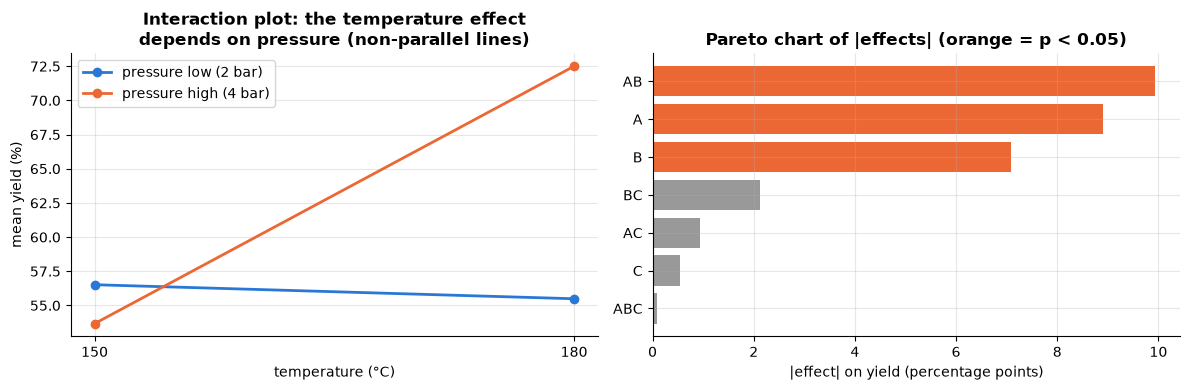

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cell = design.groupby(["A", "B"])["yield_pct"].mean().unstack()
for bval, color, lab in [(-1, PALETTE[0], "pressure low (2 bar)"), (1, PALETTE[1], "pressure high (4 bar)")]:
    axes[0].plot([150, 180], cell[bval].to_numpy(), "o-", color=color, label=lab)
axes[0].set(title="Interaction plot: the temperature effect\ndepends on pressure (non-parallel lines)",
            xlabel="temperature (°C)", ylabel="mean yield (%)", xticks=[150, 180]); axes[0].legend()
order = eff["effect (ours)"].abs().sort_values()
axes[1].barh(order.index, order.to_numpy(), color=[PALETTE[1] if p < 0.05 else "#999999" for p in eff.loc[order.index, "p-value"]])
axes[1].set(title="Pareto chart of |effects| (orange = p < 0.05)", xlabel="|effect| on yield (percentage points)")
plt.tight_layout(); plt.show()

**What just happened?** The contrast formula and the regression agree. A, B and the AB interaction are large and significant; C and the other interactions are noise around 0, exactly as the process was simulated. The interaction plot shows why OFAT fails: at low pressure raising the temperature barely changes the yield, at high pressure it helps a lot. An OFAT experimenter who varied temperature at low pressure would conclude that temperature does not matter.

### 4.1 Fractional factorials: fewer runs, deliberate aliasing

With $k = 7$ factors, a full factorial needs $2^7 = 128$ runs. A **fractional factorial $2^{k-p}$** runs only a $1/2^p$ fraction by **defining some factors as products of others** (generators). The price is **aliasing**: some effects become indistinguishable because their columns are identical.

Example $2^{4-1}$ (8 runs for 4 factors) with generator **D = ABC**. Multiplying both sides by D gives the **defining relation I = ABCD** (since $D \cdot D = I$). The alias of any effect is its product with ABCD: $A = BCD$, $AB = CD$, $AC = BD$, $AD = BC$.

**Resolution** = length of the shortest word in the defining relation:
| Resolution | Main effects aliased with | 2-factor interactions aliased with | Typical use |
|---|---|---|---|
| III | 2-factor interactions | main effects | screening many factors (risky) |
| IV | 3-factor interactions | other 2-factor interactions | screening, safe for main effects |
| V | 4-factor interactions | 3-factor interactions | estimating main effects and 2FIs |

In [11]:
base = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "B", "C"])
frac = base.assign(D=base.A * base.B * base.C)                        # generator D = ABC
print("2^(4-1) design, generator D = ABC:\n", frac.T)

cols = {}
for r in range(1, 5):
    for combo in itertools.combinations("ABCD", r):
        cols["".join(combo)] = frac[list(combo)].prod(axis=1).to_numpy()
aliases = {}
for name, v in cols.items():
    same = [other for other, w in cols.items() if other != name and np.array_equal(v, w)]
    aliases[name] = same
print("\nAlias structure (effects whose columns are identical):")
for name in ["A", "B", "C", "D", "AB", "AC", "AD"]:
    print(f"  {name:3s} = {', '.join(aliases[name])}")
print("Column of ABCD is all +1 (the identity I):", np.all(cols["ABCD"] == 1))

2^(4-1) design, generator D = ABC:
    0  1  2  3  4  5  6  7
A -1 -1 -1 -1  1  1  1  1
B -1 -1  1  1 -1 -1  1  1
C -1  1 -1  1 -1  1 -1  1
D -1  1  1 -1  1 -1 -1  1

Alias structure (effects whose columns are identical):
  A   = BCD
  B   = ACD
  C   = ABD
  D   = ABC
  AB  = CD
  AC  = BD
  AD  = BC
Column of ABCD is all +1 (the identity I): True


Aliasing can mislead. Run a **resolution III** half fraction $2^{3-1}$ (4 runs, generator **C = AB**) on our chemical process, where the true AB interaction is large and C does nothing:

In [12]:
half = pd.DataFrame(list(itertools.product([-1, 1], repeat=2)), columns=["A", "B"]).assign(C=lambda d: d.A * d.B)
rng = np.random.default_rng(30)
half["yield_pct"] = 60 + 5 * half.A + 3 * half.B + 0 * half.C + 4 * half.A * half.B + rng.normal(0, 2.0, 4)
est_C = (half.C * half.yield_pct).sum() / 2
print(half)
print(f"\nEstimated 'C effect' = {est_C:.1f} percentage points, although the catalyst does nothing:")
print("it is really C + AB (true 0 + 8) because the C column equals the AB column.")

   A  B  C  yield_pct
0 -1 -1  1  59.149282
1 -1  1 -1  55.486567
2  1 -1 -1  56.060222
3  1  1  1  71.575991

Estimated 'C effect' = 9.6 percentage points, although the catalyst does nothing:
it is really C + AB (true 0 + 8) because the C column equals the AB column.


**What just happened?** In 4 runs we "found" a big catalyst effect that is actually the temperature × pressure interaction. The standard remedies: use resolution IV or higher when interactions are plausible, run the **fold-over** fraction (flip all signs) to de-alias main effects from 2FIs, and confirm the conclusions with follow-up runs.

> 🎓 **Exam / interview tip:** "Why are fractional factorials reasonable?" → the **sparsity-of-effects** (Pareto) principle: most systems are driven by a few main effects and low-order interactions; high-order interactions are usually negligible, so aliasing them away costs little.

---
## 5. Response surface methodology (RSM) and a central composite design

> 💬 **In plain English:** fit a smooth hill to a few well-placed runs and climb to the top.

Factorial designs say which factors matter. **Response surface methodology** (Box & Wilson, 1951) finds the **best settings** by fitting a **second-order (quadratic) model** around the region of interest:

$$\hat y = b_0 + b_1 x_1 + b_2 x_2 + b_{12} x_1 x_2 + b_{11} x_1^2 + b_{22} x_2^2$$

To estimate the curvature terms you need more than 2 levels. The **central composite design (CCD)** combines
- the $2^k$ **factorial** points (±1, ±1),
- $2k$ **axial (star)** points at distance $\alpha$ on each axis (here $\alpha = \sqrt{2}$, which makes the design **rotatable**: equal prediction variance at equal distance from the centre),
- several **centre** points (they estimate pure error and check for curvature).

For $k = 2$: 4 + 4 + 5 = **13 runs**. The fitted surface's **stationary point** solves $\nabla \hat y = 0$: with $b = (b_1, b_2)$ and $B = \begin{pmatrix} b_{11} & b_{12}/2 \\ b_{12}/2 & b_{22}\end{pmatrix}$, $x_s = -\tfrac12 B^{-1} b$. If both eigenvalues of $B$ are negative it is a **maximum**.

Our simulated process (unknown to the experimenter): yield as a function of coded temperature $x_1$ (180 ± 20 °C per unit) and time $x_2$ (30 ± 10 min per unit), with a true maximum of 77.5% at $x = (0.5, 0.5)$, i.e. 190 °C and 35 min.

In [13]:
def true_yield(x1, x2):
    return 75 + 6 * x1 + 4 * x2 - 5 * x1 ** 2 - 3 * x2 ** 2 - 2 * x1 * x2

def run_process(x1, x2, rng):
    return true_yield(x1, x2) + rng.normal(0, 0.8, np.shape(x1))      # each run is noisy

a = np.sqrt(2)
ccd = pd.DataFrame(
    [(-1, -1), (1, -1), (-1, 1), (1, 1)] +                      # factorial
    [(-a, 0), (a, 0), (0, -a), (0, a)] +                        # axial
    [(0, 0)] * 5,                                               # centre
    columns=["x1", "x2"])
ccd["type"] = ["factorial"] * 4 + ["axial"] * 4 + ["centre"] * 5
rng = np.random.default_rng(2)
ccd = ccd.sample(frac=1, random_state=2).reset_index(drop=True)   # randomised run order
ccd["y"] = run_process(ccd.x1.to_numpy(), ccd.x2.to_numpy(), rng)

rsm = smf.ols("y ~ x1 + x2 + x1:x2 + I(x1**2) + I(x2**2)", data=ccd).fit()
p = rsm.params
bvec = np.array([p["x1"], p["x2"]])
Bmat = np.array([[p["I(x1 ** 2)"], p["x1:x2"] / 2], [p["x1:x2"] / 2, p["I(x2 ** 2)"]]])
xs = -0.5 * np.linalg.solve(Bmat, bvec)
eig = np.linalg.eigvalsh(Bmat)
print(rsm.params.round(3))
print(f"R² = {rsm.rsquared:.3f}")
print(f"Stationary point (coded) = {xs.round(3)} -> {180 + 20 * xs[0]:.1f} °C, {30 + 10 * xs[1]:.1f} min; "
      f"eigenvalues {eig.round(2)} -> {'maximum' if (eig < 0).all() else 'not a maximum'}")
print(f"Predicted yield there {rsm.predict(pd.DataFrame({'x1': [xs[0]], 'x2': [xs[1]]}))[0]:.2f}% | "
      f"true yield there {true_yield(*xs):.2f}% | true optimum 77.50% at (0.5, 0.5)")

Intercept     74.825
x1             6.030
x2             4.034
x1:x2         -1.863
I(x1 ** 2)    -5.244
I(x2 ** 2)    -2.444
dtype: float64
R² = 0.992
Stationary point (coded) = [0.459 0.65 ] -> 189.2 °C, 36.5 min; eigenvalues [-5.53 -2.16] -> maximum
Predicted yield there 77.52% | true yield there 77.44% | true optimum 77.50% at (0.5, 0.5)


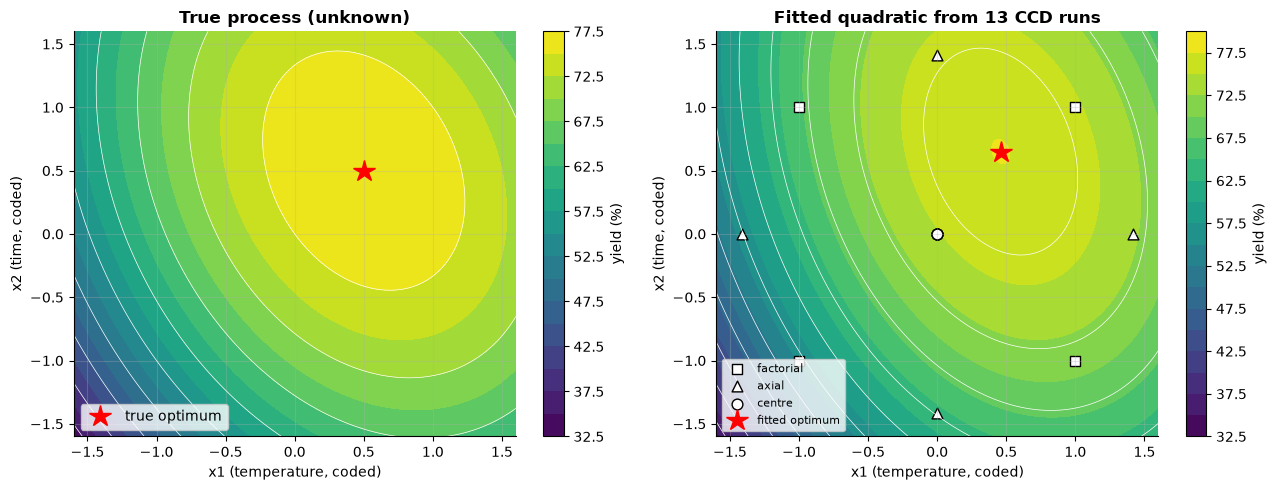

In [14]:
g1, g2 = np.meshgrid(np.linspace(-1.6, 1.6, 120), np.linspace(-1.6, 1.6, 120))
fitted = rsm.predict(pd.DataFrame({"x1": g1.ravel(), "x2": g2.ravel()})).to_numpy().reshape(g1.shape)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, Z, title in [(axes[0], true_yield(g1, g2), "True process (unknown)"), (axes[1], fitted, "Fitted quadratic from 13 CCD runs")]:
    cs = ax.contourf(g1, g2, Z, levels=20, cmap="viridis"); fig.colorbar(cs, ax=ax, label="yield (%)")
    ax.contour(g1, g2, Z, levels=10, colors="white", linewidths=0.5)
    ax.set(title=title, xlabel="x1 (temperature, coded)", ylabel="x2 (time, coded)")
for typ, mk in [("factorial", "s"), ("axial", "^"), ("centre", "o")]:
    d = ccd[ccd.type == typ]
    axes[1].scatter(d.x1, d.x2, marker=mk, color="white", edgecolor="black", s=60, label=typ)
axes[0].plot(0.5, 0.5, "r*", ms=16, label="true optimum"); axes[1].plot(*xs, "r*", ms=16, label="fitted optimum")
axes[0].legend(loc="lower left"); axes[1].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**What just happened?** Thirteen noisy runs were enough to recover the shape of the surface and an optimum close to the true 190 °C / 35 min. In practice RSM is sequential: a first-order design plus the **path of steepest ascent** moves you into the right region, then a CCD there finds the peak.

### 5.1 Compared with Bayesian optimisation

**Bayesian optimisation (BO)** (see [the Gaussian-process notebook](../03_Machine_Learning/04_uncommon_models/02_industry_gaussian_process_process_optimization.ipynb)) is **sequential**: fit a Gaussian process to the runs so far, choose the next run where the **expected improvement** is largest, repeat. Same budget of 13 runs (4 initial + 9 chosen by BO):

In [15]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

def expected_improvement(mu, sd, best, xi=0.01):
    z = (mu - best - xi) / np.maximum(sd, 1e-9)
    return (mu - best - xi) * stats.norm.cdf(z) + sd * stats.norm.pdf(z)

rng = np.random.default_rng(2)
grid = np.column_stack([g1.ravel(), g2.ravel()]) * (np.sqrt(2) / 1.6)       # candidate points in [-√2, √2]²
X_bo = rng.uniform(-1.4, 1.4, (4, 2)); y_bo = run_process(X_bo[:, 0], X_bo[:, 1], rng)
kernel = ConstantKernel(30.0, "fixed") * RBF(1.0, "fixed") + WhiteKernel(0.64, "fixed")  # fixed hyperparameters keep it simple
for it in range(9):
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True).fit(X_bo, y_bo)
    mu, sd = gp.predict(grid, return_std=True)
    x_next = grid[np.argmax(expected_improvement(mu, sd, y_bo.max()))]
    X_bo = np.vstack([X_bo, x_next]); y_bo = np.append(y_bo, run_process(x_next[0], x_next[1], rng))
gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True).fit(X_bo, y_bo)
x_best_bo = grid[np.argmax(gp.predict(grid))]
print(f"BO recommendation (coded) = {x_best_bo.round(2)}, true yield there = {true_yield(*x_best_bo):.2f}%")
print(f"CCD/RSM recommendation   = {xs.round(2)}, true yield there = {true_yield(*xs):.2f}%   (true max 77.50%)")

BO recommendation (coded) = [0.44 0.53], true yield there = 77.48%
CCD/RSM recommendation   = [0.46 0.65], true yield there = 77.44%   (true max 77.50%)


| | RSM with a CCD | Bayesian optimisation |
|---|---|---|
| Runs | planned all at once (can run in parallel, in one batch) | sequential (each run waits for the previous) |
| Model | quadratic polynomial (assumes a smooth single peak locally) | Gaussian process (flexible, any smooth shape) |
| Output | an equation with interpretable coefficients and tests | a recommended point and uncertainty map |
| Best for | few factors (2–5), local optimisation, regulated industries | expensive black-box functions, more factors, hyperparameter tuning |

Both find a good optimum here; on this simple quadratic surface RSM's model is exactly right, which is the best case for RSM. BO wins when the surface is not quadratic or the region is large.

---
## 6. Power and sample size

> 💬 **In plain English:** decide before you start how many runs you need to have a good chance of seeing the effect.

**Power** = probability of detecting an effect that really exists ($1 - \beta$). Before running an experiment, choose the sample size so that power is high (commonly 80% or 90%) for the **smallest effect worth detecting**.

For ANOVA the standard effect size is **Cohen's f** $= \sigma_{means} / \sigma$ (the standard deviation of the true group means divided by the error SD); guide values 0.10 small, 0.25 medium, 0.40 large. It relates to $\eta^2$ by $f = \sqrt{\eta^2 / (1 - \eta^2)}$. The test statistic follows a **noncentral F** distribution with noncentrality $\lambda = f^2 N$.

> Note: `statsmodels`' `FTestAnovaPower` works with the **total** number of observations `nobs`, not per group.

f = 0.25, 4 groups, alpha 0.05, power 0.80 -> N = 178.4 in total, i.e. 45 per group
Simulated power with 45 per group: 79.7%


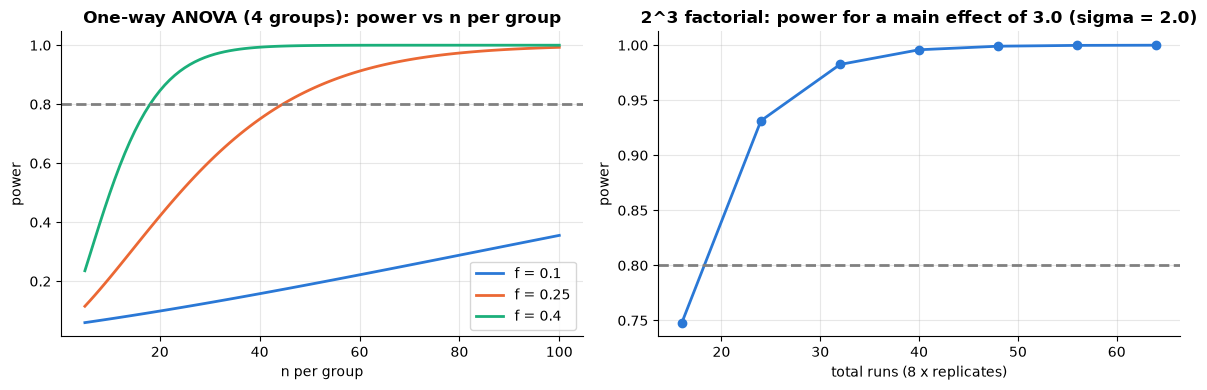

1 rep (8 runs)       NaN
2 rep (16 runs)    0.748
3 rep (24 runs)    0.931
4 rep (32 runs)    0.982
5 rep (40 runs)    0.996
6 rep (48 runs)    0.999
7 rep (56 runs)    1.000
8 rep (64 runs)    1.000


In [16]:
pa = FTestAnovaPower()
k = 4
n_total = pa.solve_power(effect_size=0.25, alpha=0.05, power=0.80, k_groups=k)
n_per = int(np.ceil(n_total / k))
print(f"f = 0.25, 4 groups, alpha 0.05, power 0.80 -> N = {n_total:.1f} in total, i.e. {n_per} per group")

# Check by simulation: 4 group means with SD of means = 0.25 when sigma = 1
offsets = np.array([-1.5, -0.5, 0.5, 1.5]); offsets = 0.25 * offsets / offsets.std()
rng = np.random.default_rng(0)
sims = rng.normal(0, 1, (4000, k, n_per)) + offsets[None, :, None]
F = (n_per * ((sims.mean(axis=2) - sims.mean(axis=(1, 2))[:, None]) ** 2).sum(axis=1) / (k - 1)) / \
    (((sims - sims.mean(axis=2, keepdims=True)) ** 2).sum(axis=(1, 2)) / (k * n_per - k))
print(f"Simulated power with {n_per} per group: {100 * (stats.f.sf(F, k - 1, k * n_per - k) < 0.05).mean():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ns = np.arange(5, 101)
for f_, c in zip([0.10, 0.25, 0.40], PALETTE):
    axes[0].plot(ns, [pa.power(effect_size=f_, nobs=n * k, alpha=0.05, k_groups=k) for n in ns], color=c, label=f"f = {f_}")
axes[0].axhline(0.8, ls="--", color="grey")
axes[0].set(title="One-way ANOVA (4 groups): power vs n per group", xlabel="n per group", ylabel="power"); axes[0].legend()

# 2^3 factorial: power to detect a main effect E (difference high - low) with r replicates
sigma, E = 2.0, 3.0
reps = np.arange(1, 9)
power_fact = []
for r in reps:
    N_runs = 8 * r; df = N_runs - 8                          # full model with all interactions
    if df == 0:
        power_fact.append(np.nan); continue
    ncp = E / (2 * sigma / np.sqrt(N_runs))                   # SE of an effect = 2 sigma / sqrt(N)
    tcrit = stats.t.ppf(0.975, df)
    power_fact.append(stats.nct.sf(tcrit, df, ncp) + stats.nct.cdf(-tcrit, df, ncp))
axes[1].plot(reps * 8, power_fact, "o-")
axes[1].axhline(0.8, ls="--", color="grey")
axes[1].set(title=f"2^3 factorial: power for a main effect of {E} (sigma = {sigma})", xlabel="total runs (8 x replicates)", ylabel="power")
plt.tight_layout(); plt.show()
print(pd.Series(power_fact, index=[f"{r} rep ({8*r} runs)" for r in reps]).round(3).to_string())

**What just happened?** The solver gives the classic answer (about 45 per group for a medium effect with 4 groups), and the simulation confirms roughly 80% power. In a factorial design **every run helps estimate every main effect** (each effect compares half of all runs with the other half), which is why factorials are so efficient: one unreplicated $2^3$ has no error df at all with the full model, but with 3 replicates (24 runs) the power for a 3-point effect is already above 90%.

> ⚠️ **Common mistake:** computing power *after* the experiment from the observed effect ("post-hoc power"). It is a one-to-one function of the p-value and adds no information. Do power analysis **before**, with the smallest effect you care about.

---
## 7. Online-experiment extensions: CUPED, switchbacks, interference

> 💬 **In plain English:** website experiments can use old data to cut noise, and need special designs when users affect each other.

Online A/B tests ([11_ab_testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb)) are CRDs with millions of units. Three classic DOE ideas take special forms there.

### 7.1 CUPED: variance reduction with pre-experiment data

**CUPED** (Controlled-experiment Using Pre-Experiment Data; Deng, Xu, Kohavi & Walker, 2013) is regression adjustment, the online cousin of **analysis of covariance (ANCOVA)**. With $X$ = the same metric measured **before** the experiment:

$$Y^{cuped} = Y - \theta\,(X - \bar X), \qquad \theta = \frac{\mathrm{Cov}(X, Y)}{\mathrm{Var}(X)}$$

Because $X$ was measured before randomisation, it is independent of the treatment, so the adjusted difference in means is still **unbiased**, while its variance shrinks by the factor $(1 - \rho^2)$, where $\rho = \mathrm{corr}(X, Y)$.

In [17]:
def simulate_ab(rng, n=2000, effect=0.4):
    pre = rng.gamma(4, 5, 2 * n)                                       # spend in the 4 weeks before the test
    treat = rng.permutation(np.repeat([0, 1], n))
    post = 0.8 * pre + effect * treat + rng.normal(0, 9, 2 * n)        # spend during the test
    return pre, post, treat

def diff_and_se(y, treat):
    a, b = y[treat == 1], y[treat == 0]
    return a.mean() - b.mean(), np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))

rng = np.random.default_rng(7)
pre, post, treat = simulate_ab(rng)
theta = np.cov(pre, post)[0, 1] / pre.var(ddof=1)
post_cuped = post - theta * (pre - pre.mean())
d0, se0 = diff_and_se(post, treat)
d1, se1 = diff_and_se(post_cuped, treat)
rho = np.corrcoef(pre, post)[0, 1]
print(f"corr(pre, post) = {rho:.2f}, theta = {theta:.2f}")
print(f"plain diff = {d0:.3f} ± {1.96 * se0:.3f} | CUPED diff = {d1:.3f} ± {1.96 * se1:.3f}")
print(f"variance ratio = {(se1 / se0) ** 2:.2f} (theory 1 - rho² = {1 - rho ** 2:.2f}) -> "
      f"same precision with about {100 * (1 - (se1 / se0) ** 2):.0f}% fewer users")

# Unbiasedness and spread over 500 repeated experiments
est = np.array([[diff_and_se(po, tr)[0],
                 diff_and_se(po - (np.cov(pr, po)[0, 1] / pr.var(ddof=1)) * (pr - pr.mean()), tr)[0]]
                for pr, po, tr in (simulate_ab(rng) for _ in range(500))])
print(f"Over 500 experiments (true effect 0.4): mean plain {est[:, 0].mean():.3f} (SD {est[:, 0].std():.3f}), "
      f"mean CUPED {est[:, 1].mean():.3f} (SD {est[:, 1].std():.3f})")

corr(pre, post) = 0.67, theta = 0.81
plain diff = 0.115 ± 0.744 | CUPED diff = 0.120 ± 0.552
variance ratio = 0.55 (theory 1 - rho² = 0.55) -> same precision with about 45% fewer users


Over 500 experiments (true effect 0.4): mean plain 0.390 (SD 0.381), mean CUPED 0.403 (SD 0.289)


**What just happened?** Pre-period spend explains a large part of the variation in test-period spend, so subtracting it removes noise that has nothing to do with the treatment: the confidence interval is much narrower and the 500-experiment simulation shows both estimators centred on the true 0.4, with CUPED far less spread out. That is why large platforms apply CUPED-style adjustment to many of their experiment metrics.

### 7.2 Interference and switchback designs

Classic DOE assumes **SUTVA** (stable unit treatment value assumption): a unit's outcome depends only on **its own** treatment. In two-sided marketplaces (ride-hailing, food delivery, ad auctions) this fails: treated users compete with control users for the **same drivers / inventory / budget**. A user-level A/B test then measures partly **stealing from control**, not the effect of launching to everyone.

A **switchback** design randomises **time slots** instead of users: in each hour (per city), *everyone* gets either treatment or control. The comparison is between treated and control **hours**, which is what a global launch would look like. Practical details: **carryover** (an hour's treatment affects the next hour, so drop a burn-in period after each switch), and analysis at the **slot** level (the slot is the experimental unit).

Simulation: a city with **100 cars per hour**. Riders open the app; a promotion raises a rider's request probability from 30% to 36%. Demand exceeds supply, so requests are served at random until cars run out.

In [18]:
def hour_rides(n_ctrl_riders, n_treat_riders, rng, cars=100, p_c=0.30, p_t=0.36):
    """Rides completed by control and treated riders in one hour with limited cars."""
    req_c, req_t = rng.binomial(n_ctrl_riders, p_c), rng.binomial(n_treat_riders, p_t)
    served = min(cars, req_c + req_t)
    served_t = rng.hypergeometric(req_t, req_c, served) if served else 0   # cars go to random requests
    return served - served_t, served_t

rng = np.random.default_rng(11)
HOURS, RIDERS = 24 * 14, 400
# (a) user-level A/B: in every hour half of the riders are treated
ab = np.array([hour_rides(RIDERS // 2, RIDERS // 2, rng) for _ in range(HOURS)])
ab_effect = ab[:, 1].sum() / (HOURS * RIDERS / 2) - ab[:, 0].sum() / (HOURS * RIDERS / 2)
# (b) switchback: each hour, all riders are control or all treated (coin flip per hour)
coin = rng.binomial(1, 0.5, HOURS)
sw = np.array([sum(hour_rides(RIDERS * (1 - c), RIDERS * c, rng)) for c in coin])
sw_effect = sw[coin == 1].mean() / RIDERS - sw[coin == 0].mean() / RIDERS
# (c) ground truth: launch to everyone vs nobody
truth = (np.mean([sum(hour_rides(0, RIDERS, rng)) for _ in range(2000)]) -
         np.mean([sum(hour_rides(RIDERS, 0, rng)) for _ in range(2000)])) / RIDERS
print(f"Rides per rider per hour, treatment minus control:")
print(f"  user-level A/B estimate : {ab_effect:+.4f}  (looks like a big win)")
print(f"  switchback estimate     : {sw_effect:+.4f}")
print(f"  true global effect      : {truth:+.4f}  (supply is the bottleneck: the promotion cannot create cars)")

Rides per rider per hour, treatment minus control:
  user-level A/B estimate : +0.0483  (looks like a big win)
  switchback estimate     : +0.0000
  true global effect      : +0.0001  (supply is the bottleneck: the promotion cannot create cars)


**What just happened?** The user-level A/B test reports a clear positive effect, but it comes from treated riders **taking cars away from control riders**. Launched to everyone, the promotion adds almost nothing because the number of cars is fixed. The switchback compares whole hours and gets close to the true global effect.

**Network effects** (social networks, messaging) cause the same problem through connections: a treated user's friends are affected too. Remedies: **cluster-randomised** designs (randomise whole communities found by graph clustering, cities, or ego-networks), and analyses that model exposure. The cost is fewer, larger units, so lower power; the clustered SEs from [notebook 13](13_statistical_modeling_and_inference.ipynb) are required.

> 🎓 **Exam / interview tip:** "Uber/Lyft/DoorDash test a new pricing algorithm. Why not a user A/B test?" → interference through shared supply violates SUTVA; use switchbacks (time × region randomisation) with burn-in, or market-level (geo) randomisation, and analyse at the slot/market level.

---
## 8. Experimenting on ML systems: a factorial ablation with ANOVA

> 💬 **In plain English:** tuning an ML model is an experiment too: vary several settings at once and let ANOVA tell you what matters.

ML papers and teams often tune or ablate **one hyperparameter at a time**, or compare single runs that differ by random seed. DOE gives a better recipe:
- treat hyperparameters as **factors** with two levels, run a **full factorial**,
- treat **random seeds / data splits as blocks** (each seed gets all configurations: same split, fair comparison),
- analyse with **ANOVA** to get main effects, **interactions** and their uncertainty.

Factors for a gradient-boosted tree classifier: learning rate (0.03 / 0.3), max depth (2 / 6), number of boosting iterations (50 / 200). $2^3 = 8$ configurations × 3 seeds = 24 training runs. (We limit the library to 1 thread so the run is fast and reproducible on a shared machine.)

In [19]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from threadpoolctl import threadpool_limits

t0 = time.perf_counter()
rows = []
with threadpool_limits(1):
    for seed in range(3):                                                      # block = seed (data + split + model)
        X, y = make_classification(n_samples=3000, n_features=20, n_informative=8, flip_y=0.05,
                                   class_sep=0.8, random_state=seed)
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=seed)
        for lr, depth, n_iter in itertools.product([0.03, 0.3], [2, 6], [50, 200]):
            clf = HistGradientBoostingClassifier(learning_rate=lr, max_depth=depth, max_iter=n_iter,
                                                 early_stopping=False, random_state=seed).fit(Xtr, ytr)
            rows.append({"seed": seed, "lr": lr, "depth": depth, "n_iter": n_iter, "acc": clf.score(Xte, yte)})
abl = pd.DataFrame(rows)
print(f"24 training runs in {time.perf_counter() - t0:.0f} s")
print(abl.groupby(["lr", "depth", "n_iter"])["acc"].mean().unstack("n_iter").round(4))

m_abl = smf.ols("acc ~ (C(lr) + C(depth) + C(n_iter))**2 + C(seed)", data=abl).fit()
aov = sm.stats.anova_lm(m_abl, typ=2)
aov["share of SS (%)"] = 100 * aov["sum_sq"] / aov["sum_sq"].sum()
print(aov.round(4))

24 training runs in 8 s
n_iter         50      200
lr   depth                
0.03 2      0.8230  0.8656
     6      0.8826  0.9041
0.30 2      0.8752  0.8896
     6      0.9011  0.9093
                    sum_sq    df        F  PR(>F)  share of SS (%)
C(lr)               0.0038   1.0  20.7330  0.0004          19.5774
C(depth)            0.0077   1.0  42.8152  0.0000          40.4288
C(n_iter)           0.0028   1.0  15.5728  0.0013          14.7048
C(seed)             0.0002   2.0   0.4610  0.6393           0.8706
C(lr):C(depth)      0.0010   1.0   5.7347  0.0301           5.4151
C(lr):C(n_iter)     0.0006   1.0   3.5676  0.0784           3.3687
C(depth):C(n_iter)  0.0003   1.0   1.5574  0.2312           1.4706
Residual            0.0027  15.0      NaN     NaN          14.1639


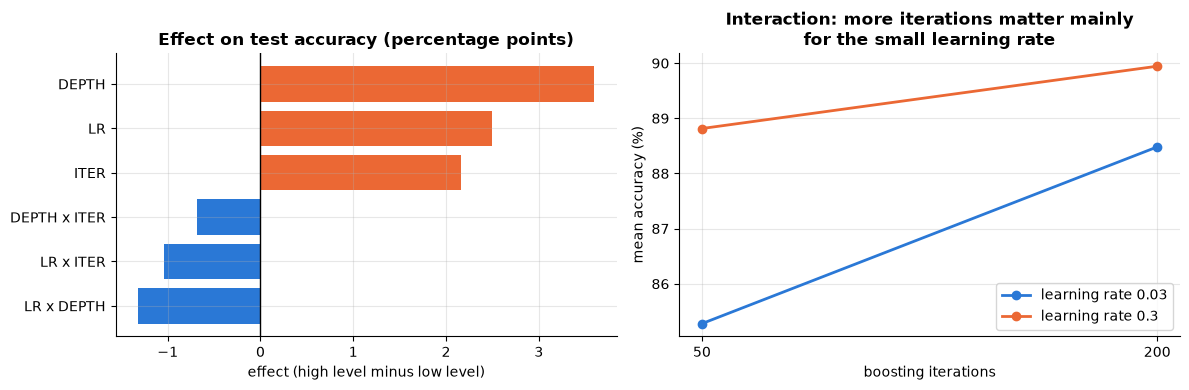

{'LR': np.float64(2.5), 'DEPTH': np.float64(3.59), 'ITER': np.float64(2.17), 'LR x DEPTH': np.float64(-1.31), 'LR x ITER': np.float64(-1.04), 'DEPTH x ITER': np.float64(-0.69)}


In [20]:
code = abl.assign(LR=np.where(abl.lr == 0.3, 1, -1), DEPTH=np.where(abl.depth == 6, 1, -1), ITER=np.where(abl.n_iter == 200, 1, -1))
effects_ml = {name: 100 * (code[list(cols)].prod(axis=1) * code.acc).sum() / (len(code) / 2)
              for name, cols in {"LR": ["LR"], "DEPTH": ["DEPTH"], "ITER": ["ITER"], "LR x DEPTH": ["LR", "DEPTH"],
                                 "LR x ITER": ["LR", "ITER"], "DEPTH x ITER": ["DEPTH", "ITER"]}.items()}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
s = pd.Series(effects_ml).sort_values()
axes[0].barh(s.index, s.to_numpy(), color=[PALETTE[1] if v > 0 else PALETTE[0] for v in s])
axes[0].axvline(0, color="black", lw=1)
axes[0].set(title="Effect on test accuracy (percentage points)", xlabel="effect (high level minus low level)")
cell = abl.groupby(["lr", "n_iter"])["acc"].mean().unstack()
for lr_, c in zip(cell.index, PALETTE):
    axes[1].plot([50, 200], 100 * cell.loc[lr_].to_numpy(), "o-", color=c, label=f"learning rate {lr_}")
axes[1].set(title="Interaction: more iterations matter mainly\nfor the small learning rate",
            xlabel="boosting iterations", ylabel="mean accuracy (%)", xticks=[50, 200]); axes[1].legend()
plt.tight_layout(); plt.show()
print({k: round(v, 2) for k, v in effects_ml.items()})

**What just happened?** With only 24 runs we learn, with uncertainty, which knobs matter: read the ANOVA table and the effects chart (depth has the largest main effect here, then learning rate and iterations; the learning rate × depth interaction is significant and learning rate × iterations points the same way with p ≈ 0.08: a small learning rate needs more iterations and deeper trees to catch up). The seed block is small, meaning the comparison across configurations is fair within each seed. An OFAT ablation ("change one knob from the default") would report different conclusions depending on where the other knobs were set.

Good practice for ML experiments (see also [24_Research_Methods/02](../24_Research_Methods/02_experiment_design_for_ml.ipynb)):
- several seeds per configuration, seeds as blocks, report means with CIs, not the best seed,
- factorial or fractional-factorial designs for ablations; RSM or BO for tuning continuous knobs,
- a fixed, untouched test set; the ANOVA is on validation results if you will use them to choose.

---
## 9. 🔗 How this connects to modern AI

> 💬 **In plain English:** these ideas run the A/B tests, tuning and evaluation behind modern AI products.

- **Online experiments** on recommendation systems, search ranking and LLM-product features are DOE at scale: CUPED for variance reduction, switchbacks for marketplaces, cluster designs for social features ([11_ab_testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb), [industry A/B report](../03_Machine_Learning/11_ab_testing/02_industry_ab_test_analysis_report.ipynb)).
- **Hyperparameter search**: factorial and fractional designs for ablations, Latin-hypercube sampling (a space-filling cousin of the Latin square) to start Bayesian optimisation, and BO itself ([GP process optimisation](../03_Machine_Learning/04_uncommon_models/02_industry_gaussian_process_process_optimization.ipynb)).
- **LLM evaluation**: prompts × models × decoding settings form a factorial design; questions are blocks (every model answers the same questions), and the analysis should be paired/blocked, not pooled.
- **Causal inference** ([10_causal_inference](../03_Machine_Learning/10_causal_inference/01_causal_inference.ipynb)) starts where randomisation is impossible; DOE is the gold standard it tries to imitate.
- **Industry 4.0 / manufacturing ML**: RSM and DOE remain standard in process engineering, and their data feed the ML models that monitor the process.

## Recap

- **Randomise, replicate, block, control.** Randomisation protects against confounding; blocking removes known nuisance variation; replication estimates the noise.
- **CRD + one-way ANOVA**: $F = MS_T / MS_E$; follow a significant F with **Tukey HSD** (all pairs) or Dunnett (vs control).
- **RCBD** removes one nuisance factor, a **Latin square** removes two with only $t^2$ runs; the gain is measured by the drop in $MS_E$ (relative efficiency) and by higher power.
- **2^k factorials** estimate all main effects and interactions efficiently; effect = 2 × coded regression coefficient; non-parallel interaction plots reveal interactions.
- **Fractional factorials** save runs through aliasing; know the **defining relation** and **resolution** (III, IV, V).
- **RSM with a CCD** fits a quadratic surface and finds the optimum; **Bayesian optimisation** is the sequential, model-flexible alternative.
- **Power** analysis comes before the experiment; Cohen's f and `FTestAnovaPower` (total N!) for ANOVA.
- Online: **CUPED** cuts variance by $1 - \rho^2$; **switchbacks** or cluster designs handle **interference**.
- ML ablations are factorial experiments: seeds as blocks, ANOVA for effects and interactions.

## Practice problems

**1. (Easy, conceptual)** A school tests 3 teaching methods. Each of 6 schools has 3 classes; within each school the methods are assigned to classes at random; the final exam score of each student is recorded. Name the factor, its levels, the blocks, the experimental unit and the response. Why is "number of students" not the right replication count?

<details><summary>Show solution</summary>

Factor: teaching method; levels: the 3 methods; blocks: schools; experimental unit: the **class** (the method is assigned to a whole class); response: exam score (analyse the class mean, or use a mixed model with students nested in classes). Students in one class share the teacher and the lessons, so they are not independent replicates of the method: using them as replicates is **pseudo-replication**. The real replication is 6 classes per method.

</details>

**2. (Easy, coding)** Write `f_test(groups)` computing the one-way ANOVA F and p from scratch, and check it on `[[12, 14, 11, 13], [15, 17, 16, 18], [12, 13, 15, 12]]` against `scipy.stats.f_oneway`.

<details><summary>Show solution</summary>

```python
import numpy as np
from scipy import stats

def f_test(groups):
    allv = np.concatenate(groups); grand = allv.mean()
    ss_t = sum(len(g) * (np.mean(g) - grand) ** 2 for g in groups)
    ss_e = sum(((np.asarray(g) - np.mean(g)) ** 2).sum() for g in groups)
    df1, df2 = len(groups) - 1, len(allv) - len(groups)
    F = (ss_t / df1) / (ss_e / df2)
    return F, stats.f.sf(F, df1, df2)

g = [[12, 14, 11, 13], [15, 17, 16, 18], [12, 13, 15, 12]]
print(f_test([np.array(x, float) for x in g]))
```

</details>

**3. (Medium, coding)** A $2^{5-2}$ design uses base factors A, B, C and generators D = AB, E = AC. Write a function that finds every effect whose column equals each main effect's column. What is the resolution?

<details><summary>Show solution</summary>

```python
import itertools
import numpy as np

def alias_table(base_factors, generators):
    """generators: dict like {"D": "AB", "E": "AC"}. Returns {effect: [aliases]} for main effects."""
    runs = np.array(list(itertools.product([-1, 1], repeat=len(base_factors))))
    cols = {f: runs[:, i] for i, f in enumerate(base_factors)}
    for new, word in generators.items():
        cols[new] = np.prod([cols[c] for c in word], axis=0)
    names = sorted(cols)
    words = {}
    for r in range(1, len(names) + 1):
        for combo in itertools.combinations(names, r):
            words["".join(combo)] = np.prod([cols[c] for c in combo], axis=0)
    return {f: [w for w, v in words.items() if w != f and np.array_equal(v, words[f])] for f in names}

table = alias_table("ABC", {"D": "AB", "E": "AC"})
for f, al in table.items():
    print(f, "=", [a for a in al if len(a) <= 2])
```
Defining relation: I = ABD = ACE = BCDE (the last is the product of the first two). The shortest word has 3 letters, so the design is **resolution III**: main effects are aliased with two-factor interactions (A = BD = CE, D = AB, ...). Use it only for screening, and de-alias with a fold-over if needed.

</details>

**4. (Medium, coding)** Implement `cuped(y, x)` returning the adjusted metric and θ, and show on simulated data (x ~ N(50, 10), y = 0.6x + N(0, 8)) that the variance ratio equals $1 - \rho^2$.

<details><summary>Show solution</summary>

```python
import numpy as np

def cuped(y, x):
    theta = np.cov(x, y)[0, 1] / np.var(x, ddof=1)
    return y - theta * (x - x.mean()), theta

rng = np.random.default_rng(0)
x = rng.normal(50, 10, 5000)
y = 0.6 * x + rng.normal(0, 8, 5000)
y_adj, theta = cuped(y, x)
rho = np.corrcoef(x, y)[0, 1]
print(round(theta, 3), round(y_adj.var() / y.var(), 3), round(1 - rho ** 2, 3))
```
With σ_x = 10, Var(0.6x) = 36 and noise variance 64, so ρ² = 36/100 = 0.36 and the variance drops to about 64%.

</details>

**5. (Medium, conceptual)** You run a switchback test of a new dispatch algorithm with 1-hour slots. Dispatch decisions in one hour change where drivers are at the start of the next hour. What problem is this, and how do you handle it?

<details><summary>Show solution</summary>

**Carryover**: the outcome of a slot depends on the treatment of the previous slot, so treated and control slots are contaminated near the switches. Remedies: discard a **burn-in** window at the start of each slot (e.g. the first 10–15 minutes) from the analysis; choose slot lengths longer than the carryover time; use randomisation schedules balanced over time of day and day of week; model the previous slot's treatment as a covariate; analyse at the slot level with SEs that respect time correlation.

</details>

**6. (Easy, coding)** How many observations per group are needed for a one-way ANOVA with 3 groups, Cohen's f = 0.25, α = 0.05 and 90% power?

<details><summary>Show solution</summary>

```python
import numpy as np
from statsmodels.stats.power import FTestAnovaPower

n_total = FTestAnovaPower().solve_power(effect_size=0.25, alpha=0.05, power=0.90, k_groups=3)
print(round(n_total, 1), "in total ->", int(np.ceil(n_total / 3)), "per group")
```
Remember that `FTestAnovaPower` returns the **total** N.

</details>

**7. (Medium, coding)** Write `is_latin(sq)` and `latin_square(t, seed)` (random Latin square from a cyclic one with shuffled rows, columns and symbols) and test them for t = 2..8.

<details><summary>Show solution</summary>

```python
import numpy as np

def is_latin(sq):
    sq = np.asarray(sq); t = len(sq)
    symbols = set(np.unique(sq))
    return (len(symbols) == t and all(set(sq[i]) == symbols for i in range(t))
            and all(set(sq[:, j]) == symbols for j in range(t)))

def latin_square(t, seed=0):
    rng = np.random.default_rng(seed)
    base = (np.arange(t)[:, None] + np.arange(t)[None, :]) % t
    return rng.permutation(t)[base[rng.permutation(t)][:, rng.permutation(t)]]

print(latin_square(5))
```
Shuffling rows, columns and symbols of a Latin square always gives another Latin square, but this method does not produce **every** Latin square with equal probability for t ≥ 4 (that needs e.g. the Jacobson–Matthews Markov chain); for experimental design it is the usual practice.

</details>

**8. (Hard, conceptual)** An engineer varies temperature with pressure fixed at its default, picks the best temperature, then varies pressure at that temperature (OFAT). Using the chemical process of Section 4, explain why this can miss the optimum, and how many runs a $2^2$ factorial with 3 replicates needs compared with OFAT at 3 levels per factor with 3 replicates.

<details><summary>Show solution</summary>

With a strong A × B interaction, the best temperature depends on the pressure. OFAT explores only a cross through the design space, never the corner where both are high, and it cannot estimate the interaction at all, so it can stop at a point that is optimal only along each line. A $2^2$ factorial with 3 replicates needs **12 runs** and estimates both main effects and the interaction, each using all 12 runs. OFAT with 3 levels per factor and 3 replicates needs 3 × 3 (temperature sweep) + 2 × 3 (two new pressure levels) = **15 runs**, and each effect is estimated from only part of the data.

</details>

## Further reading

- D. C. Montgomery, *Design and Analysis of Experiments*, 10th ed. (Wiley, 2019): Ch. 3 (ANOVA), 4 (blocks, Latin squares), 6–8 (2^k and fractional factorials), 11 (response surfaces).
- G. E. P. Box, J. S. Hunter & W. G. Hunter, *Statistics for Experimenters*, 2nd ed. (Wiley, 2005).
- R. Kohavi, D. Tang & Y. Xu, *Trustworthy Online Controlled Experiments* (Cambridge, 2020): CUPED, interference, switchbacks.
- A. Deng, Y. Xu, R. Kohavi & T. Walker (2013), "Improving the Sensitivity of Online Controlled Experiments by Utilizing Pre-Experiment Data", *WSDM*.
- Free: the [NIST/SEMATECH e-Handbook of Statistical Methods](https://www.itl.nist.gov/div898/handbook/), Chapter 5 "Process Improvement" (DOE).

## Next notebook

➡️ [15_data_visualization_principles_and_storytelling.ipynb](15_data_visualization_principles_and_storytelling.ipynb): turn your results into charts and a story that decision-makers understand.